# 03 · Modelagem e decisão

**Pergunta do notebook:** qual modelo estima melhor a chance de calote, e como transformar essa chance numa decisão que dá dinheiro?

> Notebook em construção ao longo das Etapas 9 a 14. Na Etapa 20 ele vira a narrativa final do projeto.

**Como rodar:** os experimentos levam alguns minutos. Com `RERUN_EXPERIMENTS = False`, o notebook **lê os resultados já salvos** em `reports/` (gerados por `make experiments`). Com `True`, refaz tudo do zero.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk import config
from credit_risk.experiments import model_duel
from credit_risk.explain import odds_ratio_table, vif_table
from credit_risk.features import engineered_features
from credit_risk.models import CATALOG
from credit_risk.split import load_train
from credit_risk.viz import CONTEXT, HIGHLIGHT, INK_2, SURFACE, pct, save, set_style

RERUN_EXPERIMENTS = False

set_style()
pd.set_option("display.precision", 4)
df = load_train()
y = df[config.TARGET]

## 1. O duelo: quatro modelos, as mesmas 15 rodadas

| Modelo | Como pensa |
|---|---|
| **Regressão logística** | soma ponderada das variáveis, convertida numa probabilidade |
| **Árvore de Decisão** | uma sequência de perguntas sim/não ("atrasou 2 meses?") |
| **Random Forest** | centenas de árvores, cada uma treinada numa amostra diferente; a resposta é a média |
| **XGBoost** | árvores em sequência, cada uma corrigindo os erros da anterior |

Todos usam as mesmas features (Etapa 7) e o pré-processamento adequado (Etapa 8), **sem tuning** (fica para a Etapa 11). A **referência** é um "modelo" que dá a todo cliente a taxa média (22%), ou seja, o equivalente a dizer "ninguém dá calote".

**Métricas** (todas medidas na parte de cada rodada que o modelo **não** viu):

| Métrica | Pergunta que responde | Chute |
|---|---|---|
| **PR AUC** (principal) | acha os inadimplentes sem acusar bons pagadores? | 0,22 |
| ROC AUC | ordena bem quem tem mais risco? | 0,50 |
| **KS** | qual a maior separação entre bons e maus ao longo do score? (padrão do mercado de crédito) | 0 |
| Brier | as probabilidades são confiáveis? (erro quadrático; **menor é melhor**) | 0,17 |
| Acurácia | que fração acerta com corte em 50%? | 0,78 |

**Critérios fixados antes:** líder = maior PR AUC médio; um rival está **empatado** se vencer o líder em pelo menos 40% das rodadas. Hipótese: XGBoost ≥ Random Forest > logística > Árvore de Decisão.

In [2]:
if RERUN_EXPERIMENTS:
    model_duel()
summary = pd.read_csv(config.REPORTS_DIR / "model_duel_summary.csv")
folds = pd.read_csv(config.REPORTS_DIR / "model_duel_folds.csv")
cols = [
    "nome",
    "pr_auc_media",
    "roc_auc_media",
    "ks_media",
    "brier_media",
    "accuracy_media",
    "ganho_vs_xgboost",
    "win_rate_vs_xgboost",
]
summary[cols]

,nome,pr_auc_media,roc_auc_media,ks_media,brier_media,accuracy_media,ganho_vs_xgboost,win_rate_vs_xgboost
0,XGBoost,0.5626,0.7871,0.4397,0.1333,0.8215,NaN,NaN
1,Random Forest,0.5623,0.7879,0.4399,0.1332,0.8217,-0.0003,0.5333
2,Regressão logística,0.5476,0.7756,0.4266,0.1351,0.8219,-0.0150,0.0000
3,Árvore de Decisão,0.5256,0.7723,0.4196,0.1369,0.8177,-0.0370,0.0000
4,Referência (taxa média),0.2212,0.5000,0.0000,0.1723,0.7788,-0.3414,0.0000


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_01_duelo_pr_auc.png')

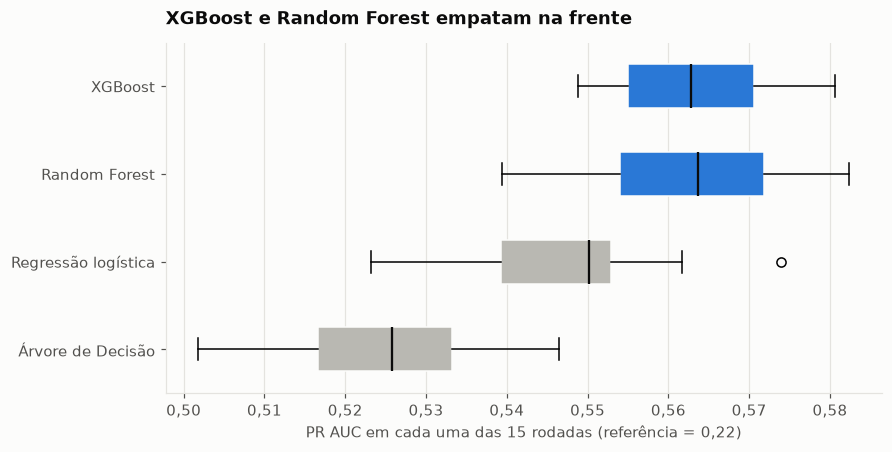

In [3]:
order = [m for m in summary["modelo"] if m != "dummy"]
leader = order[0]
fig, ax = plt.subplots(figsize=(8, 4))
data = [folds.loc[folds["modelo"] == m, "pr_auc"] for m in order]
bp = ax.boxplot(
    data,
    orientation="horizontal",
    patch_artist=True,
    widths=0.5,
    medianprops={"color": "#0b0b0b", "linewidth": 1.5},
)
for patch, m in zip(bp["boxes"], order, strict=True):
    patch.set_facecolor(HIGHLIGHT if m in ("xgboost", "random_forest") else CONTEXT)
    patch.set_edgecolor(SURFACE)
ax.set_yticks(range(1, len(order) + 1), [CATALOG[m].label for m in order])
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
ax.set_xlabel("PR AUC em cada uma das 15 rodadas (referência = 0,22)")
ax.set_title("XGBoost e Random Forest empatam na frente")
save(fig, "model_01_duelo_pr_auc")

**Evidência:**
- **XGBoost** lidera em PR AUC (0,5626), mas a **Random Forest** fica a 0,0003 e vence o XGBoost em **8 das 15 rodadas** (53%): **empate** pelo critério. Ela é até um pouco melhor em ROC AUC, KS e Brier.
- A **logística** perde para o XGBoost em todas as 15 rodadas, mas por pouco (−0,015). A **Árvore de Decisão** fica atrás de todos.
- A hipótese registrada antes se confirma: XGBoost ≈ Random Forest > logística > árvore.
- Todos ficam **muito acima da referência** (0,22): o modelo sabe algo que a taxa média não sabe.

**Decisão:** **XGBoost e Random Forest seguem empatados para o tuning** (Etapa 11). A logística continua como modelo **interpretável** de comparação.

## 2. Por que a acurácia engana (de novo, agora com modelos)

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_02_acuracia_engana.png')

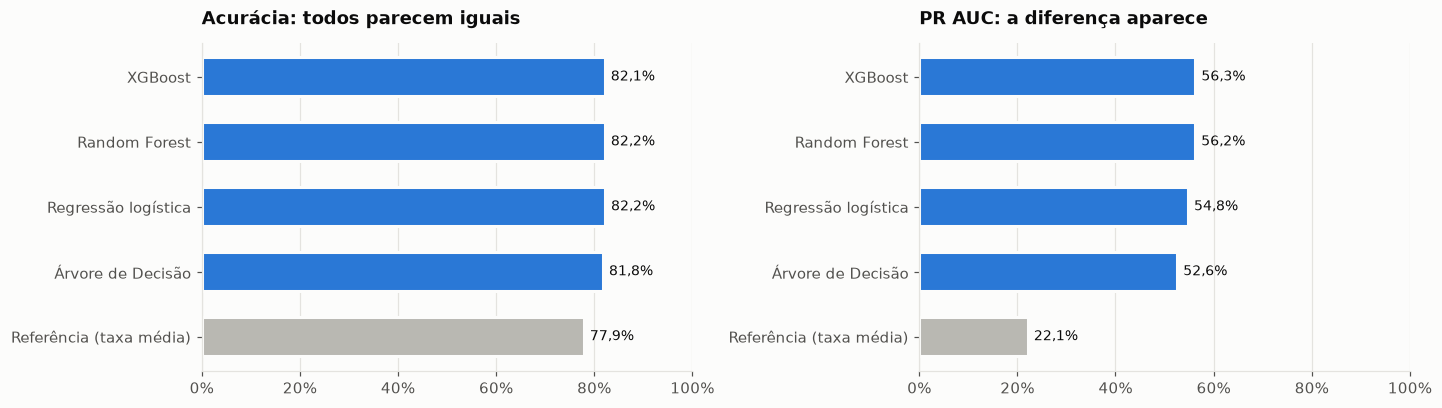

In [4]:
plot = summary.set_index("modelo").loc[order + ["dummy"]]
labels = [CATALOG[m].label for m in plot.index]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, metric, title in [
    (axes[0], "accuracy_media", "Acurácia: todos parecem iguais"),
    (axes[1], "pr_auc_media", "PR AUC: a diferença aparece"),
]:
    colors = [CONTEXT if m == "dummy" else HIGHLIGHT for m in plot.index]
    ax.barh(labels, plot[metric], color=colors, height=0.6, edgecolor=SURFACE, linewidth=2)
    for i, v in enumerate(plot[metric]):
        ax.annotate(
            pct(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9
        )
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
save(fig, "model_02_acuracia_engana")

**Evidência:** a acurácia dos quatro modelos fica entre 81,8% e 82,2%, só 4 p.p. acima de "ninguém dá calote" (77,9%). O modelo com **maior acurácia é a logística**, que tem PR AUC **pior** que os dois líderes. Já o PR AUC separa claramente os modelos da referência (0,22 → 0,56).

**Por quê:** a acurácia usa um corte fixo em 50% e conta acertos iguais para os dois lados. Com 78% de bons pagadores, acertar "não vai dar calote" é fácil. O que o negócio precisa é **ordenar o risco** e ter **probabilidades confiáveis** para calcular o custo (Etapa 12).

## 3. O que a regressão logística ensina: razões de chances

A grande vantagem da logística é ser **interpretável**: cada variável recebe um peso, e `exp(peso)` é a **razão de chances** (*odds ratio*), o número pelo qual a chance de calote é multiplicada quando a variável aumenta 1 unidade, mantendo as outras iguais.

Exemplo: chance de 1 para 4 (20%) com razão de chances 2 vira 2 para 4 (33%).

### Primeiro, um cuidado: multicolinearidade

Se duas variáveis medem quase a mesma coisa (ex.: "pior atraso" e "meses com atraso"), o modelo divide o peso entre elas de forma arbitrária, e cada coeficiente sozinho perde o sentido. Isso **não prejudica a previsão**, só a leitura.

O **VIF** (*fator de inflação da variância*) mede isso. A ideia vem da álgebra linear: tenta-se explicar cada coluna com as outras (uma regressão). Se elas explicam 90% dela (R² = 0,9), o VIF é 1 ÷ (1 − 0,9) = **10**. Acima de 5 é o alerta usual.

In [5]:
E = engineered_features(df)
vif_all = vif_table(E)
vif_all.round(1).to_frame()

,vif
util_recent,19.2
pay_ratio_mean,18.2
util_mean,16.3
revolving_months,16.2
delay_months,10.4
pay_ratio_recent,5.9
delay_max,3.7
delay_recent,3.5
util_trend,3.5
paid_full_all,3.4


**Evidência:** várias features de resumo passam muito do alerta (VIF de 10 a 19). Faz sentido: meses no rotativo, meses com atraso e meses quitando somam 6, então um é quase determinado pelos outros. Na logística completa, por exemplo, `delay_months` (a variável mais forte sozinha) aparece com peso **negativo**, um artefato da colinearidade.

**Decisão:** para **interpretar**, uso uma **logística enxuta** com 5 variáveis de VIF baixo, ajustada com `statsmodels` para ter intervalo de confiança em cada razão de chances. Para **prever**, os modelos completos continuam como estão.

In [6]:
X_int = E[config.INTERPRETABLE_FEATURES]
print("VIF do conjunto enxuto:")
print(vif_table(X_int).round(2).to_string())
odds = odds_ratio_table(X_int, y)
print(f"\npseudo-R²: {odds.attrs['pseudo_r2']:.3f}")
odds.round(4)

VIF do conjunto enxuto:
util_mean         2.65
pay_ratio_mean    2.46
delay_months      2.27
delay_recent      2.11
log_limit         1.28



pseudo-R²: 0.160


,razao_chances,ic_inf,ic_sup,p_valor
delay_recent,1.9926,1.8801,2.1118,0.0000
delay_months,1.3308,1.2937,1.3689,0.0000
log_limit,0.7794,0.7491,0.8108,0.0000
util_mean,1.1468,0.9790,1.3434,0.0896
pay_ratio_mean,1.2843,1.1190,1.4741,0.0004


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_03_razoes_chances.png')

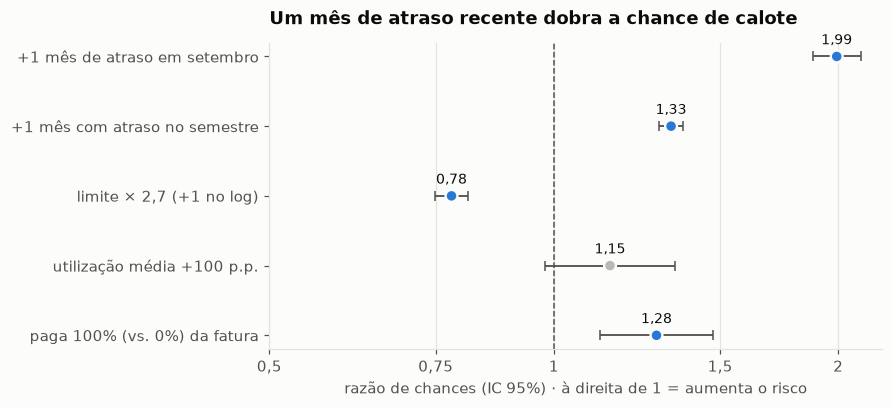

In [7]:
labels_or = {
    "delay_recent": "+1 mês de atraso em setembro",
    "delay_months": "+1 mês com atraso no semestre",
    "log_limit": "limite × 2,7 (+1 no log)",
    "util_mean": "utilização média +100 p.p.",
    "pay_ratio_mean": "paga 100% (vs. 0%) da fatura",
}
plot_or = odds.loc[config.INTERPRETABLE_FEATURES[::-1]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ys = range(len(plot_or))
signif = plot_or["p_valor"] < config.ALPHA
ax.errorbar(
    plot_or["razao_chances"],
    ys,
    xerr=[
        plot_or["razao_chances"] - plot_or["ic_inf"],
        plot_or["ic_sup"] - plot_or["razao_chances"],
    ],
    fmt="none",
    ecolor=INK_2,
    elinewidth=1.2,
    capsize=3,
)
ax.scatter(
    plot_or["razao_chances"],
    ys,
    s=60,
    zorder=3,
    color=[HIGHLIGHT if s else CONTEXT for s in signif],
    edgecolor=SURFACE,
    linewidth=1.5,
)
for i, v in enumerate(plot_or["razao_chances"]):
    ax.annotate(
        f"{v:.2f}".replace(".", ","),
        (v, i),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
ax.axvline(1, color=INK_2, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2], ["0,5", "0,75", "1", "1,5", "2"])
ax.minorticks_off()
ax.set_yticks(list(ys), [labels_or[f] for f in plot_or.index])
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("razão de chances (IC 95%) · à direita de 1 = aumenta o risco")
ax.set_title("Um mês de atraso recente dobra a chance de calote")
save(fig, "model_03_razoes_chances")

**Leitura para o negócio** (cada efeito mantém as outras variáveis iguais):

| Variável | Razão de chances | Tradução |
|---|---|---|
| Atraso em setembro | **≈ 2,0** | cada mês de atraso no último pagamento **dobra** a chance de calote |
| Meses com atraso no semestre | **≈ 1,33** | cada mês do semestre com atraso aumenta a chance em cerca de 33%, **além** do atraso de setembro |
| Limite (log) | **≈ 0,78** | dobrar o limite reduz a chance em cerca de 16% (0,78 elevado a 0,69). Lembrete: é associação, não causa; o banco já dava limite maior a quem considerava melhor |
| Utilização média | ≈ 1,15, **não significativa** | depois de considerar o atraso, usar mais o limite não muda o risco de forma clara |
| Fração paga da fatura | **≈ 1,28** | ⚠️ **contraintuitivo**: sozinho, pagar mais "protege" (EDA); comparando clientes com o **mesmo atraso**, o efeito se inverte |

**O último achado é um caso clássico de confusão:** o efeito protetor de pagar a fatura era, em grande parte, **o atraso disfarçado**. Quem paga pouco costuma atrasar. Quando o modelo já sabe do atraso, pagar mais da fatura deixa de indicar menos risco. Fica registrado como resultado; não forço uma explicação.

O pseudo-R² de 0,16 parece baixo, mas é comum em crédito: o comportamento das pessoas tem muita variação que nenhum dado captura. O que importa para a decisão é **ordenar** bem o risco (PR AUC, KS) e ter **probabilidades confiáveis** (Brier, Etapa 12).

## 4. Conclusões da Etapa 9

| # | Achado | Decisão |
|---|---|---|
| 1 | XGBoost (PR AUC 0,563) e Random Forest (0,562) **empatam** (RF vence 53% das rodadas) | os dois seguem para o tuning |
| 2 | Logística 0,548 e Árvore de Decisão 0,526; todos muito acima da referência (0,22) | logística fica como modelo interpretável |
| 3 | Acurácia de 81,8% a 82,2% em todos; a **maior** é a da logística | acurácia não é critério de escolha |
| 4 | Features de resumo são muito colineares (VIF até 19) | coeficientes da logística completa não são lidos um a um |
| 5 | Logística enxuta: atraso recente **dobra** a chance; dobrar o limite reduz ≈ 16% | base para os motivos da decisão (Etapa 15) |
| 6 | Com o atraso no modelo, pagar mais da fatura não reduz o risco | o atraso é o que importa |

## 5. Balancear as classes ajuda? (Etapa 10)

Só 22% dos clientes dão calote. Uma recomendação comum é **balancear** para o modelo "prestar mais atenção" nos inadimplentes:
- **Pesos por classe** (*class_weight*): cada erro num inadimplente conta cerca de 3,5 vezes mais no treino.
- **SMOTE**: cria inadimplentes **sintéticos**, interpolando entre inadimplentes parecidos, até as classes ficarem do mesmo tamanho. Aplicado **só no treino de cada fold**.

**O porém:** as duas técnicas fazem o modelo acreditar num mundo com 50% de caloteiros, e as probabilidades tendem a sair **infladas**. A decisão por custo (Etapa 12) multiplica a probabilidade pela dívida; probabilidade inflada vira ação em quem não precisa.

**Critério fixado antes:** adotar só se o PR AUC subir com win rate > 60% **e** o Brier não piorar (win rate ≥ 50%). **Hipótese:** não melhora o PR AUC e piora o Brier.

In [8]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import balancing_calibration, balancing_experiment

    balancing_experiment()
    balancing_calibration()
decision = pd.read_csv(config.REPORTS_DIR / "balancing_decision.csv")
calib = pd.read_csv(config.REPORTS_DIR / "balancing_calibration.csv")
decision.round(4)

,modelo,estrategia,ganho_pr_auc,win_rate_pr_auc,ganho_brier,win_rate_brier,pr_auc_ok,brier_ok,adotar
0,logistic,class_weight,-0.0028,0.0000,-0.0478,0.0,False,False,False
1,logistic,smote,-0.0034,0.1333,-0.0478,0.0,False,False,False
2,random_forest,class_weight,0.0003,0.6000,-0.0391,0.0,False,False,False
3,random_forest,smote,-0.0143,0.0000,-0.0080,0.0,False,False,False
4,xgboost,class_weight,0.0005,0.5333,-0.0410,0.0,False,False,False
5,xgboost,smote,-0.0052,0.0667,-0.0017,0.0,False,False,False


In [9]:
mean_prob = calib.groupby(["modelo", "estrategia"])["media_prevista"].first().unstack()
mean_prob = mean_prob[["none", "class_weight", "smote"]]
mean_prob.index = [CATALOG[m].label for m in mean_prob.index]
print(f"Taxa real de default no treino: {y.mean():.2%}")
(mean_prob * 100).round(1).rename(
    columns={"none": "nenhum (%)", "class_weight": "class_weight (%)", "smote": "SMOTE (%)"}
)

Taxa real de default no treino: 22.12%


estrategia,nenhum (%),class_weight (%),SMOTE (%)
Regressão logística,22.1,43.3,43.1
Random Forest,22.2,40.7,29.1
XGBoost,22.1,40.8,25.0


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_04_confiabilidade_balanceamento.png')

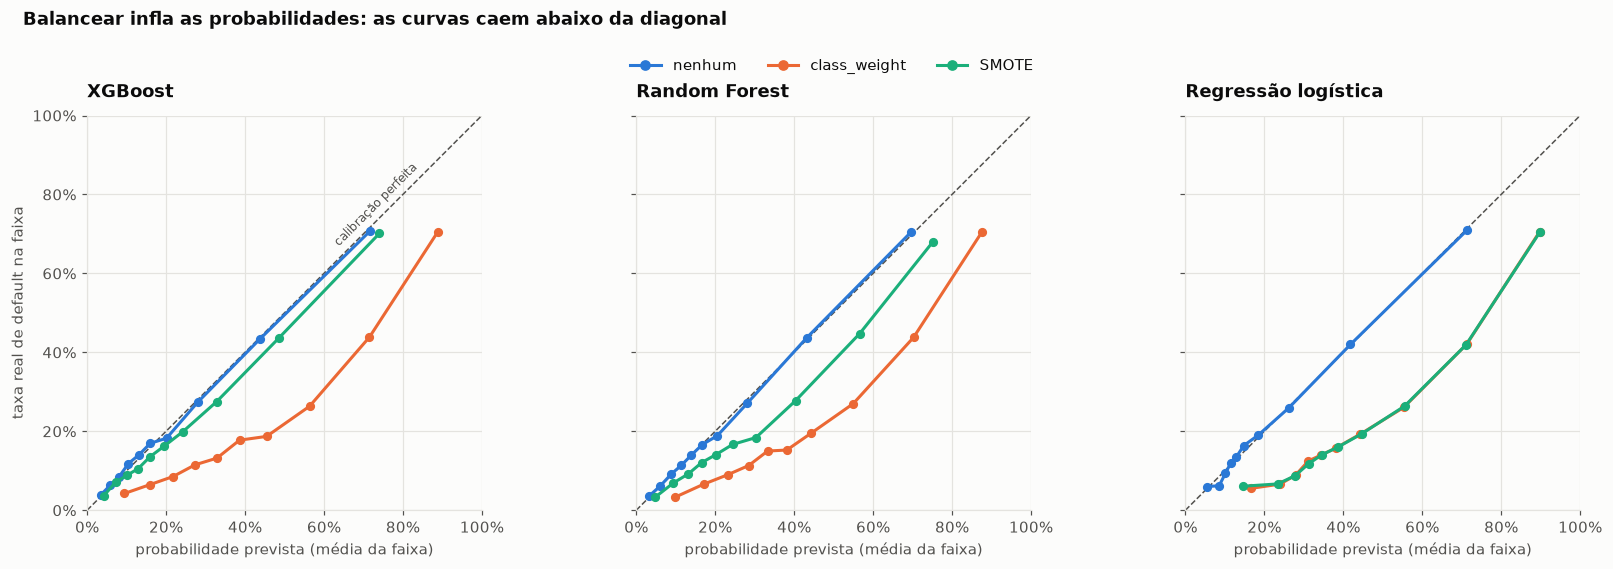

In [10]:
strategy_style = {
    "none": (HIGHLIGHT, "nenhum"),
    "class_weight": ("#eb6834", "class_weight"),
    "smote": ("#1baf7a", "SMOTE"),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, model in zip(axes, ["xgboost", "random_forest", "logistic"], strict=True):
    ax.plot([0, 1], [0, 1], color=INK_2, linestyle="--", linewidth=1)
    for strategy, (color, label) in strategy_style.items():
        part = calib[(calib["modelo"] == model) & (calib["estrategia"] == strategy)]
        ax.plot(
            part["prevista"],
            part["observada"],
            marker="o",
            markersize=5,
            linewidth=2,
            color=color,
            label=label,
        )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.grid(axis="x")
    ax.set_xlabel("probabilidade prevista (média da faixa)")
    ax.set_title(CATALOG[model].label)
axes[0].set_ylabel("taxa real de default na faixa")
axes[0].annotate("calibração perfeita", (0.62, 0.67), rotation=45, fontsize=8, color=INK_2)
handles = [plt.Line2D([], [], color=c, marker="o", linewidth=2) for c, _ in strategy_style.values()]
fig.legend(
    handles,
    [lbl for _, lbl in strategy_style.values()],
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.07),
)
fig.suptitle(
    "Balancear infla as probabilidades: as curvas caem abaixo da diagonal",
    x=0.01,
    ha="left",
    fontweight="bold",
    y=1.14,
)
save(fig, "model_04_confiabilidade_balanceamento")

In [11]:
row = calib[(calib["modelo"] == "xgboost") & (calib["faixa"] == 6)].set_index("estrategia")
row[["prevista", "observada", "n"]].round(3)

,prevista,observada,n
estrategia,,,
none,0.201,0.182,2400
class_weight,0.455,0.187,2400
smote,0.243,0.199,2400


**Evidência:**
- **PR AUC:** nenhuma técnica melhora de forma consistente. O melhor caso (Random Forest + class_weight) ganha 0,0003 e vence em 60% das rodadas, sem passar do critério (> 60%). O SMOTE **piora** o PR AUC em quase todas as rodadas dos três modelos.
- **Brier:** piora em **100% das rodadas**, em todas as variantes. Com class_weight, o Brier do XGBoost (0,174) fica **pior que o da referência** que dá 22% para todo mundo (0,172).
- **Probabilidade média:** sem balanceamento, os modelos preveem em média **22%**, igual à taxa real. Com class_weight, **41% a 43%**. Na curva de confiabilidade, as linhas balanceadas ficam muito abaixo da diagonal. Na logística, class_weight e SMOTE produzem curvas praticamente iguais (se sobrepõem no gráfico).
- **Exemplo real** (XGBoost, 7ª faixa de risco): sem balanceamento o modelo diz 20% e a taxa real é 18%; com class_weight, diz **45%** para os mesmos clientes, cuja taxa real é **19%**.

**O que isso faria com o dinheiro** (exemplo ilustrativo, com valores hipotéticos): um cliente deve NT$ 10.000 e a perda em caso de calote seria de 60%. Com a probabilidade real de 19%, a perda esperada é 0,19 × 0,60 × 10.000 = **NT$ 1.140**. Com a probabilidade inflada de 45%, o cálculo diria **NT$ 2.700**, mais que o dobro, e a política agiria em muitos clientes que não precisam.

**Decisão:** **nenhum balanceamento** (`config.BALANCING_STRATEGY = "none"`). A hipótese se confirmou nos dois pontos. Para achar mais inadimplentes, o caminho certo é **mover o limiar de decisão** (Etapa 12) com probabilidades calibradas, e não distorcer o treino.

## 6. Ajuste fino dos hiperparâmetros (Etapa 11, Parte A)

Até aqui os modelos usaram configurações "de fábrica". O **tuning** testa combinações de hiperparâmetros e fica com a melhor:
- **Grid** (testa todas as combinações) para a logística (7 valores de `C`) e para a árvore (24 combinações);
- **Randomized** (sorteia combinações num espaço amplo) para a Random Forest (40) e o XGBoost (60).

**O risco: o otimismo da busca.** Escolher o melhor entre 60 candidatos é como jogar 60 dados e ficar com o maior: parte da "vitória" é sorte nos folds usados. Por isso a busca usa folds sorteados com **outra semente** (2024), e a versão escolhida é reavaliada nos **folds padrão** (semente 42), que a busca nunca viu. A diferença entre as duas notas é o **otimismo**.

**Critério fixado antes:** a versão ajustada substitui a padrão só se o PR AUC subir com win rate > 60% e o Brier não piorar. **Hipóteses:** ganho ≤ 0,01; otimismo positivo.

In [12]:
if RERUN_EXPERIMENTS:
    from credit_risk.tuning import run_tuning, tuned_leader_duel

    run_tuning()
    tuned_leader_duel()
tuning = pd.read_csv(config.REPORTS_DIR / "tuning_results.csv")
tuning.drop(columns="params").round(4)

,modelo,candidatos,pr_auc_busca,pr_auc_padrao,pr_auc_ajustado,otimismo,ganho_pr_auc,win_rate_pr_auc,ganho_brier,win_rate_brier,adotar
0,logistic,7,0.5468,0.5476,0.5476,-0.0007,0.0000,0.0000,0.0000,0.0000,False
1,decision_tree,24,0.5410,0.5256,0.5376,0.0034,0.0120,1.0000,0.0006,0.7333,True
2,random_forest,40,0.5652,0.5623,0.5642,0.0010,0.0019,0.6667,0.0001,0.7333,True
3,xgboost,60,0.5662,0.5626,0.5657,0.0005,0.0031,0.7333,0.0002,0.7333,True


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_05_tuning.png')

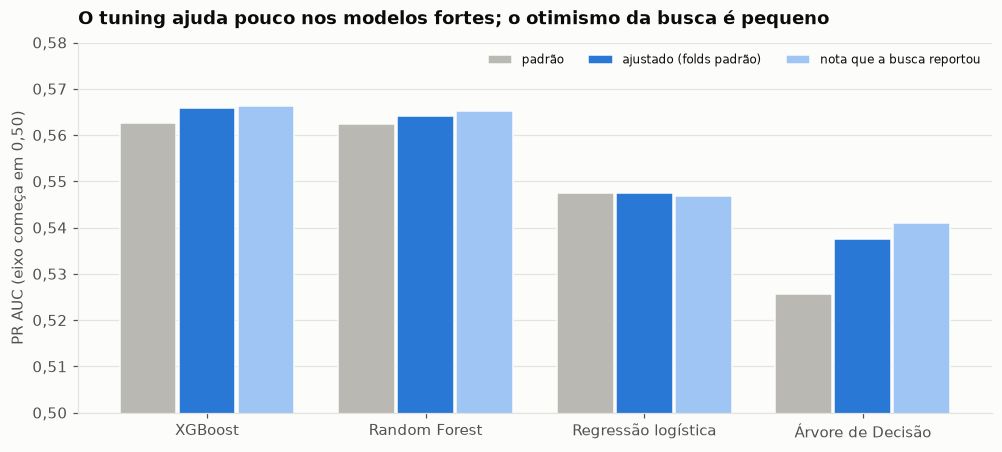

In [13]:
tun = tuning.set_index("modelo").loc[["xgboost", "random_forest", "logistic", "decision_tree"]]
labels_t = [CATALOG[m].label for m in tun.index]
x = np.arange(len(tun))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.27, tun["pr_auc_padrao"], 0.26, color=CONTEXT, label="padrão", edgecolor=SURFACE)
ax.bar(
    x,
    tun["pr_auc_ajustado"],
    0.26,
    color=HIGHLIGHT,
    label="ajustado (folds padrão)",
    edgecolor=SURFACE,
)
ax.bar(
    x + 0.27,
    tun["pr_auc_busca"],
    0.26,
    color="#9ec5f4",
    label="nota que a busca reportou",
    edgecolor=SURFACE,
)
ax.set_xticks(x, labels_t)
ax.set_ylim(0.50, 0.58)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
ax.set_ylabel("PR AUC (eixo começa em 0,50)")
ax.legend(loc="upper right", ncol=3, fontsize=8)
ax.set_title("O tuning ajuda pouco nos modelos fortes; o otimismo da busca é pequeno")
save(fig, "model_05_tuning")

In [14]:
duel = pd.read_csv(config.REPORTS_DIR / "tuned_duel.csv")
duel.round(4)

,lider,rival,métrica,base,candidato,ganho_medio,desvio_ganho,win_rate
0,xgboost,random_forest,pr_auc,0.5657,0.5642,-0.0016,0.0031,0.3333
1,xgboost,random_forest,roc_auc,0.7885,0.7874,-0.0011,0.0009,0.0667
2,xgboost,random_forest,ks,0.4401,0.4391,-0.0010,0.0040,0.4000
3,xgboost,random_forest,brier,0.1330,0.1331,-0.0001,0.0004,0.4667


**Evidência:**
- **XGBoost:** 0,5626 → **0,5657** (+0,003, vence em 73% das rodadas). **Random Forest:** 0,5623 → **0,5642** (+0,002, 67%). Os dois passam no critério, sem piorar o Brier.
- **Árvore de Decisão:** o maior ganho (+0,012, 100% das rodadas), justamente o modelo mais sensível à configuração. A busca escolheu árvores mais profundas (10 níveis) com folhas maiores (≥ 200 clientes).
- **Logística:** a busca escolheu **C = 1**, o próprio valor padrão. Não há o que adotar.
- **Otimismo:** a nota da busca fica 0,0005 a 0,0034 **acima** da nota real nos folds independentes, como esperado. Na logística ele saiu levemente **negativo** (−0,0007): com só 7 candidatos, a "sorte" da escolha quase não atua, e o que aparece é a variação natural entre sorteios de folds. Hipótese **parcialmente** confirmada: o otimismo existe, mas é pequeno nestes dados.
- **Depois do tuning, o empate se desfaz:** a Random Forest ajustada vence o XGBoost ajustado em só **33%** das rodadas de PR AUC (abaixo dos 40% para empate) e em 1 de 15 em ROC AUC.

**Decisão:** hiperparâmetros ajustados adotados para XGBoost, Random Forest e árvore (`reports/best_params.json`). **O XGBoost ajustado é o líder isolado** e o modelo de referência para a Parte B (combinação) e para a calibração (Etapa 12).